# **Phần 1 – Câu hỏi lý thuyết:**

## **Câu 1:**

### *1.1. Miền không gian (Spatial Domain):*

Miền không gian là cách biểu diễn ảnh trực tiếp bằng **giá trị cường độ của các pixel trong mặt phẳng ảnh**.

Ảnh được biểu diễn dưới dạng hàm:

$f(x, y)$

Trong đó:

- (x, y) là tọa độ pixel.
- f(x, y) là mức xám tại pixel đó.

Trong miền này, các thao tác xử lý ảnh thường thực hiện **trực tiếp trên pixel**, ví dụ:

- Làm mờ ảnh (smoothing)
- Tăng độ sắc nét (sharpening)
- Thay đổi độ sáng / tương phản
- Lọc trung bình hoặc lọc Gaussian

### *1.2. Miền tần số (Frequency Domain):*

Miền tần số biểu diễn ảnh dưới dạng các thành phần tần số không gian sau khi áp dụng Two-Dimensional Fourier Transform.

Ảnh được biểu diễn:

$F(u, v)$

Trong đó:

- u, v là tọa độ tần số
- F(u, v) biểu diễn biên độ của các thành phần tần số trong ảnh

Thay vì mô tả ảnh bằng pixel, miền tần số mô tả ảnh bằng các sóng sin và cos có tần số khác nhau.

Trong miền này, các thao tác xử lý ảnh thường bao gồm:

- Làm mờ ảnh (smoothing)
- Tăng độ sắc nét (sharpening)
- Thay đổi độ sáng / tương phản
- Lọc trung bình hoặc lọc Gaussian


### *2.1. Thành phần tần số thấp (Low Frequency Components):*

Các thành phần tần số thấp thường nằm gần tâm phổ Fourier.

Tần số thấp dùng để biểu diễn:

- Cấu trúc tổng thể của ảnh.
- Vùng sáng tối lớn.
- Sự thay đổi cường độ chậm.

Nếu chỉ giữ lại tần số thấp và loại bỏ tần số cao, ảnh sẽ:

- Bị mờ.
- Mất chi tiết.

Nguyên lý này thường được sử dụng trong các kỹ thuật lọc làm mượt (smoothing) trong xử lý ảnh, giúp:

- Giảm nhiễu.
- Làm ảnh mịn hơn.

### *2.2. Thành phần tần số cao (High Frequency Components):*

Các thành phần tần số cao thường nằm xa tâm phổ Fourier.

Tần số cao dùng để biểu diễn:

- Chi tiết nhỏ trong ảnh.
- Biên (edges) của vật thể.
- Texture (hoa văn bề mặt).
- Vùng có sự thay đổi cường độ nhanh.

Nếu chỉ giữ lại tần số cao:

- Ảnh sẽ nhấn mạnh biên.
- Các chi tiết sắc nét được tăng cường.

Nguyên lý này thường được áp dụng trong các phương pháp lọc tăng cường biên (sharpening) trong xử lý ảnh.

## **Câu 2:**

Phải sử dụng phép logarithm trong quá trình hiển thị phổ Fourier vì:

Biên độ của phổ Fourier có dải giá trị rất lớn:

- Các tần số thấp (gần tâm phổ) thường có giá trị rất lớn.
- Các tần số cao có giá trị nhỏ hơn rất nhiều.

Nếu hiển thị trực tiếp:

$|F(u,v)|$

thì:

- Vùng gần tâm phổ sẽ rất sáng.
- Các thành phần tần số nhỏ ở xa tâm gần như không nhìn thấy.

Phép logarithm giúp nén dải giá trị (dynamic range):

- Làm giảm sự chênh lệch giữa giá trị lớn và nhỏ.
- Giúp các thành phần tần số cao trở nên rõ hơn.

Nhờ đó, phổ Fourier dễ quan sát và phân tích hơn, có thể nhìn thấy cả tần số thấp và tần số cao trong cùng một ảnh.

Thành phần +1 trong log⁡〖(1+|F(u,v)|)〗 giúp tránh trường hợp tính log⁡0  khi biên độ bằng 0.

# **Phần 2 — Thiết kế các bộ lọc thông thấp:**

## **Câu 3 — Bộ lọc thông thấp hình tròn (Circular Low-pass Filter):**

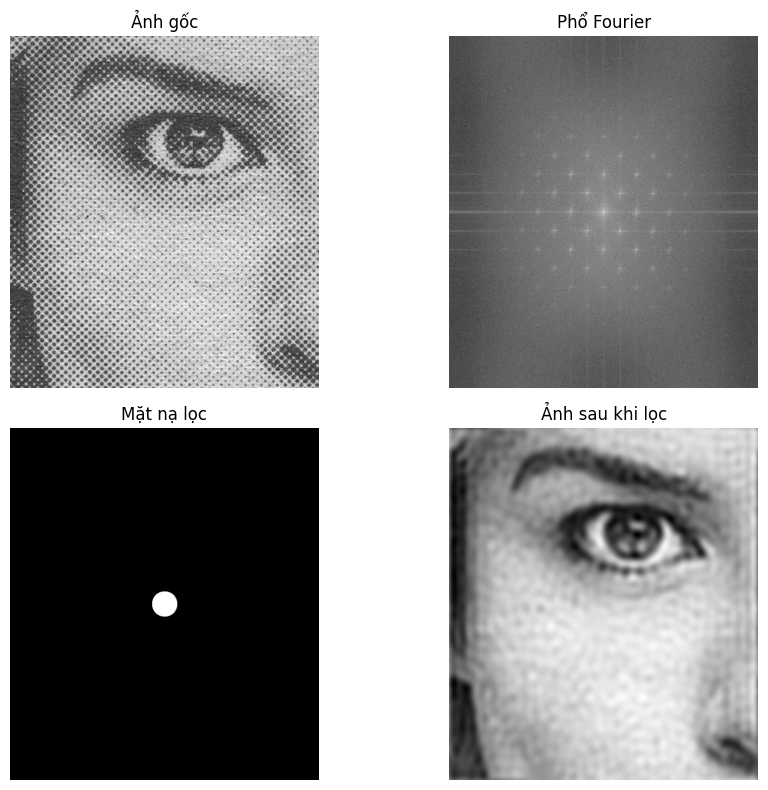

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Đọc ảnh
img_path = r"Fig0422(newspaper_shot_woman).tif"

img = Image.open(img_path).convert("L")
img = np.array(img)

M, N = img.shape

# 2. Fourier Transform
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

spectrum = np.log(1 + np.abs(F_shift))

# 3. Tạo Circular Low-pass Filter
D0 = 30

u = np.arange(M)
v = np.arange(N)
U, V = np.meshgrid(u, v, indexing='ij')

center_u = M // 2
center_v = N // 2

D = np.sqrt((U-center_u)**2 + (V-center_v)**2)

H = (D <= D0).astype(int)

# 4. Áp dụng bộ lọc
G = H * F_shift

G_ishift = np.fft.ifftshift(G)
img_filtered = np.fft.ifft2(G_ishift)
img_filtered = np.abs(img_filtered)

# 5. Hiển thị kết quả
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.title("Ảnh gốc")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("Phổ Fourier")
plt.imshow(spectrum, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Mặt nạ lọc")
plt.imshow(H, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Ảnh sau khi lọc")
plt.imshow(img_filtered, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

## **Câu 4 — Bộ lọc thông thấp hình vuông (Square Low-pass Filter):**

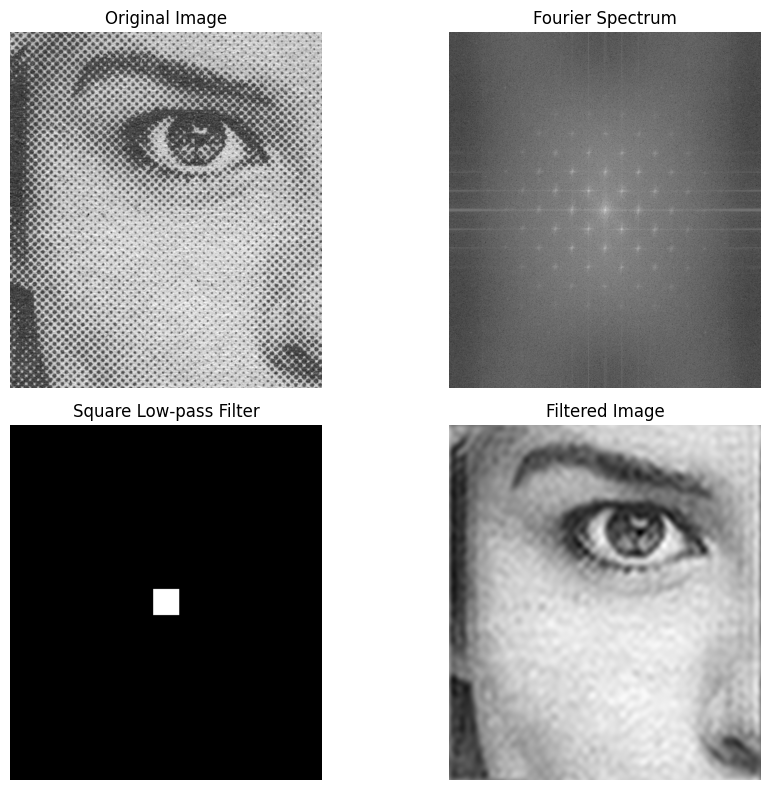

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Đọc ảnh
img_path = r"Fig0422(newspaper_shot_woman).tif"

img = Image.open(img_path).convert("L")
img = np.array(img)

M, N = img.shape

# 2. Fourier Transform
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

spectrum = np.log(1 + np.abs(F_shift))

# 3. Tạo Square Low-pass Filter
a = 30

u = np.arange(M)
v = np.arange(N)

U, V = np.meshgrid(u, v, indexing='ij')

center_u = M // 2
center_v = N // 2

H_square = ((np.abs(U - center_u) <= a) &
            (np.abs(V - center_v) <= a)).astype(int)

# 4. Áp dụng bộ lọc
G = H_square * F_shift

G_ishift = np.fft.ifftshift(G)
img_filtered = np.fft.ifft2(G_ishift)
img_filtered = np.abs(img_filtered)

# 5. Hiển thị kết quả
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.title("Original Image")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("Fourier Spectrum")
plt.imshow(spectrum, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Square Low-pass Filter")
plt.imshow(H_square, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Filtered Image")
plt.imshow(img_filtered, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### **So sánh Circular Low-pass Filter và Square Low-pass Filter:**

#### **1. Hình dạng mặt nạ lọc:**

##### Circular Low-pass Filter:
- Mặt nạ có dạng hình tròn.  
- Khoảng cách được tính theo khoảng cách Euclidean từ tâm phổ tần số.

##### Square Low-pass Filter:
- Mặt nạ có dạng hình vuông.  
- Điều kiện lọc dựa trên `|u − M/2|` và `|v − N/2|` theo trục ngang và dọc.

#### **2. Phân bố tần số được giữ lại:**

##### Circular Filter:
- Giữ các tần số thấp theo mọi hướng đồng đều.  
- Phù hợp với đặc tính phổ tần số của ảnh tự nhiên.

##### Square Filter:
- Giữ tần số theo trục ngang và trục dọc.  
- Một số tần số ở góc chéo có thể bị loại bỏ hoặc giữ lại không đồng đều.

#### **3. Chất lượng ảnh sau khi lọc:**

##### Circular Low-pass Filter:
- Ảnh mượt và tự nhiên hơn.
- Nhiễu dạng halftone pattern (chấm báo) được giảm khá tốt.
- Biên ảnh vẫn tương đối mềm mại.

##### Square Low-pass Filter:
- Ảnh cũng được*làm mịn, nhưng:
        - Có thể xuất hiện artifact nhẹ theo hướng ngang và dọc.
        - Một số chi tiết có thể bị mất hoặc biến dạng nhẹ do vùng lọc không tròn.

#### **4. Hiệu quả lọc nhiễu:**

##### Circular Filter:
- Loại bỏ nhiễu tần số cao đồng đều hơn.
- Kết quả thường ổn định và tự nhiên hơn.

##### Square Filter:
- Lọc nhanh và đơn giản.
- Nhưng hiệu quả không đồng đều theo mọi hướng.

#### **5. Kết luận:**
- Circular Low-pass Filter thường cho kết quả tốt hơn Square Low-pass Filter vì nó giữ lại các thành phần tần số thấp một cách đồng đều theo mọi hướng trong miền tần số, giúp ảnh sau khi lọc mượt và tự nhiên hơn.

- Trong khi đó, Square Low-pass Filter có vùng lọc dạng hình vuông nên việc giữ và loại bỏ tần số không đối xứng theo mọi hướng, dẫn đến khả năng xuất hiện artifact hoặc biến dạng nhẹ trong ảnh.

## **Câu 5 — Gaussian Low-pass Filter:**

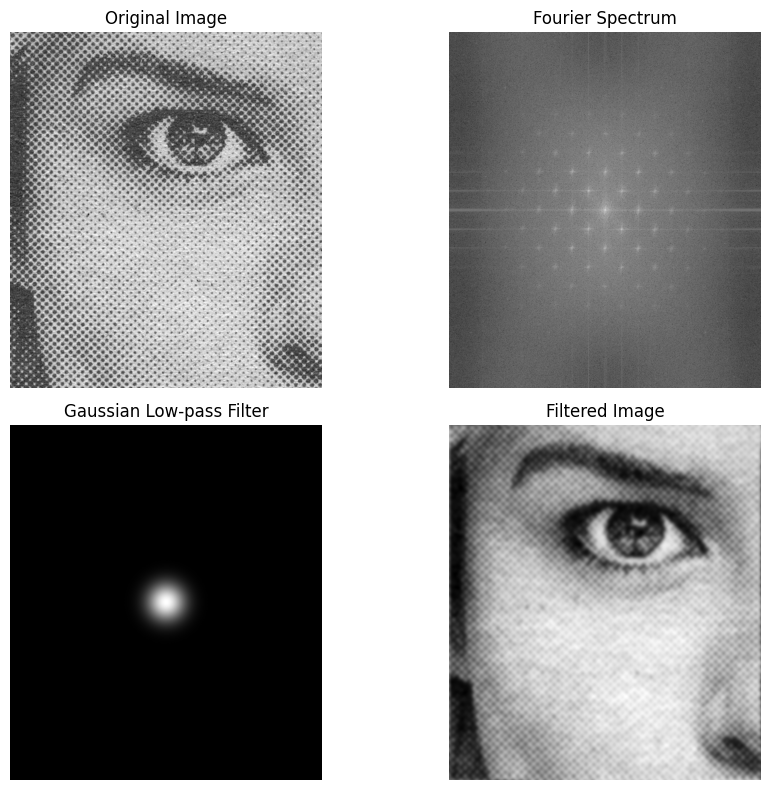

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Đọc ảnh
img_path = r"Fig0422(newspaper_shot_woman).tif"

img = Image.open(img_path).convert("L")
img = np.array(img)

M, N = img.shape

# 2. Fourier Transform
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

spectrum = np.log(1 + np.abs(F_shift))

# 3. Tạo Gaussian Low-pass Filter
D0 = 30

u = np.arange(M)
v = np.arange(N)

U, V = np.meshgrid(u, v, indexing='ij')

center_u = M // 2
center_v = N // 2

D = np.sqrt((U - center_u)**2 + (V - center_v)**2)

H_gaussian = np.exp(-(D**2) / (2*(D0**2)))

# 4. Áp dụng bộ lọc
G = H_gaussian * F_shift

G_ishift = np.fft.ifftshift(G)
img_filtered = np.fft.ifft2(G_ishift)
img_filtered = np.abs(img_filtered)

# 5. Hiển thị kết quả
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.title("Original Image")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("Fourier Spectrum")
plt.imshow(spectrum, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Gaussian Low-pass Filter")
plt.imshow(H_gaussian, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Filtered Image")
plt.imshow(img_filtered, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### **Nhận xét:**

#### **Độ mượt của ảnh:**

- Gaussian Low-pass Filter làm mượt ảnh bằng cách giảm dần các thành phần tần số cao theo hàm Gaussian. Vì vậy, ảnh sau khi lọc mượt và tự nhiên hơn so với bộ lọc thông thấp lý tưởng.

#### **So sánh với Ideal Filter:**

- Ideal Low-pass Filter có ranh giới cắt tần số đột ngột, nên có thể gây hiện tượng ringing (gợn sóng) trong ảnh.

Trong khi đó, Gaussian Low-pass Filter giảm các thành phần tần số cao một cách từ từ, do đó:
- Ít gây artifact hơn.

- Kết quả mượt và tự nhiên hơn.

## **Câu 6 — Butterworth Low-pass Filter:**

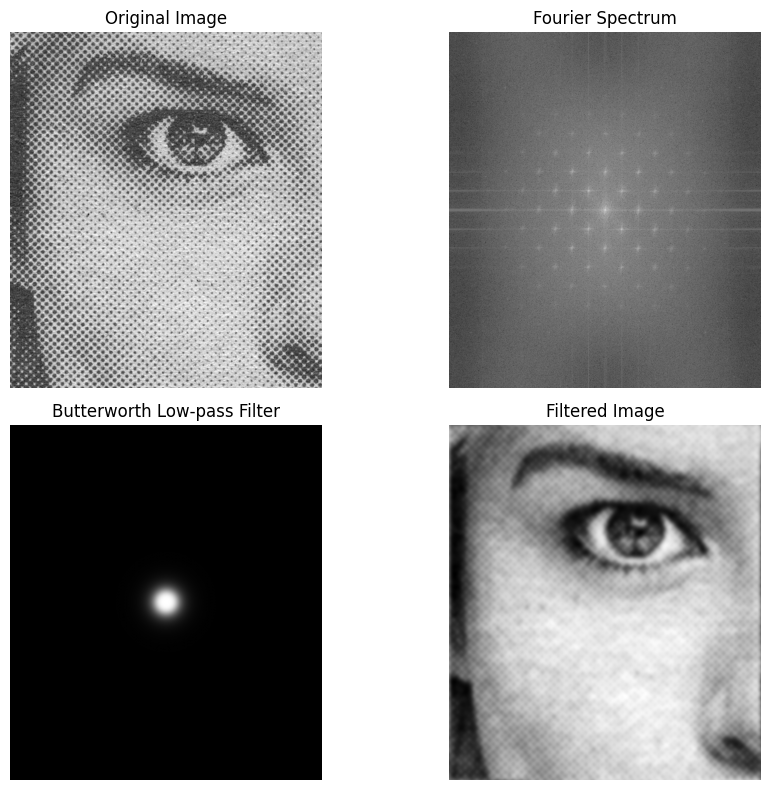

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Đọc ảnh
img_path = r"Fig0422(newspaper_shot_woman).tif"

img = Image.open(img_path).convert("L")
img = np.array(img)

M, N = img.shape

# 2. Fourier Transform
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

spectrum = np.log(1 + np.abs(F_shift))

# 3. Tạo Butterworth Low-pass Filter
D0 = 30
n = 2

u = np.arange(M)
v = np.arange(N)

U, V = np.meshgrid(u, v, indexing='ij')

center_u = M // 2
center_v = N // 2

D = np.sqrt((U - center_u)**2 + (V - center_v)**2)

H_butterworth = 1 / (1 + (D / D0)**(2*n))

# 4. Áp dụng bộ lọc
G = H_butterworth * F_shift

G_ishift = np.fft.ifftshift(G)
img_filtered = np.fft.ifft2(G_ishift)
img_filtered = np.abs(img_filtered)

# 5. Hiển thị kết quả
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.title("Original Image")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("Fourier Spectrum")
plt.imshow(spectrum, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Butterworth Low-pass Filter")
plt.imshow(H_butterworth, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Filtered Image")
plt.imshow(img_filtered, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### **So sánh kết quả:**

#### **So với Ideal Circular Filter:**
- Ideal Filter có biên cắt tần số rất đột ngột.  

- Điều này dễ gây ra hiện tượng ringing artifact (gợn sóng) trong ảnh.  

- Butterworth Filter có đường chuyển tiếp mềm hơn, nên giảm hiện tượng ringing so với Ideal Filter.

#### **So với Gaussian Filter:**
- Gaussian Filter có đường cong chuyển tiếp mượt nhất.  

- Butterworth Filter nằm giữa Ideal và Gaussian:
  - Mềm hơn Ideal Filter.
  - Nhưng sắc nét hơn Gaussian Filter.

# **Phần 3 — Phân tích kết quả:**

## **Câu 7:**

### **So sánh các bộ lọc thông thấp:**

#### **1. Circular Low-pass Filter (Ideal Filter):**

##### *Mức độ làm mượt ảnh:*
- Bộ lọc Circular (Ideal Low-pass Filter) loại bỏ hoàn toàn các tần số cao bên ngoài bán kính \(D_0\). Vì vậy, ảnh sau khi lọc trở nên mượt hơn và giảm đáng kể các chi tiết nhiễu tần số cao.

##### *Khả năng giữ lại chi tiết:*
- Do việc cắt tần số diễn ra rất đột ngột tại ngưỡng \(D_0\), một số chi tiết quan trọng của ảnh cũng có thể bị mất. Điều này làm ảnh trở nên hơi mờ và giảm độ sắc nét.

##### *Hiện tượng ringing artifact:*
- Circular filter thường gây ra ringing artifact (hiện tượng gợn sóng quanh biên ảnh). Nguyên nhân là do sự thay đổi đột ngột giữa vùng giữ tần số và vùng loại bỏ tần số trong miền tần số.

#### **2. Square Low-pass Filter:**

##### *Mức độ làm mượt ảnh:*
- Square Low-pass Filter cũng loại bỏ các thành phần tần số cao nhưng theo vùng hình vuông. Ảnh sau khi lọc được làm mịn nhưng mức độ mượt không đồng đều theo mọi hướng.

##### *Khả năng giữ lại chi tiết:*
- Do vùng lọc có dạng hình vuông, một số tần số ở các hướng chéo có thể bị giữ hoặc loại bỏ không hợp lý. Điều này làm cho khả năng giữ chi tiết của ảnh kém ổn định hơn so với bộ lọc hình tròn.

##### *Hiện tượng ringing artifact:*
- Square filter cũng có thể gây ra ringing artifact và đôi khi tạo ra các artifact theo hướng ngang và dọc, do biên của vùng lọc không đối xứng theo mọi hướng.

#### **3. Gaussian Low-pass Filter:**

##### *Mức độ làm mượt ảnh:*
- Gaussian Low-pass Filter làm mượt ảnh theo hàm Gaussian, trong đó các tần số cao bị giảm dần một cách liên tục thay vì bị cắt đột ngột. Vì vậy ảnh sau khi lọc thường mượt và tự nhiên hơn so với các bộ lọc lý tưởng.

##### *Khả năng giữ lại chi tiết:*
- Do quá trình suy giảm tần số diễn ra từ từ, Gaussian filter vẫn giữ lại được nhiều chi tiết quan trọng của ảnh hơn so với Ideal filter.

##### *Hiện tượng ringing artifact:*
- Gaussian filter hầu như không gây ra ringing artifact vì không có sự thay đổi đột ngột trong miền tần số.

#### **4. Butterworth Low-pass Filter:**

##### *Mức độ làm mượt ảnh:*
- Butterworth Low-pass Filter có độ dốc chuyển tiếp giữa vùng giữ và vùng loại bỏ tần số, phụ thuộc vào bậc \(n\). Với \(n = 2\), ảnh sau khi lọc được làm mịn nhưng vẫn giữ được nhiều chi tiết hơn so với Ideal filter.

##### *Khả năng giữ lại chi tiết:*
Butterworth filter giữ lại chi tiết tốt hơn Ideal filter vì đường chuyển tiếp mềm hơn. Tuy nhiên khả năng giữ chi tiết vẫn kém hơn một chút so với Gaussian filter.

##### *Hiện tượng ringing artifact:*
Butterworth filter có thể xuất hiện ringing artifact, nhưng ít hơn so với Ideal filter, vì sự chuyển tiếp giữa các tần số không quá đột ngột.

### **Kết luận:**
- Circular (Ideal) Filter: làm mượt mạnh nhưng dễ gây ringing artifact và mất chi tiết.  

- Square Filter: làm mượt nhưng không đồng đều theo mọi hướng và có thể xuất hiện artifact theo trục.  

- Gaussian Filter: cho kết quả mượt và tự nhiên nhất, gần như không gây ringing artifact.  

- Butterworth Filter: là sự cân bằng giữa Ideal và Gaussian, vừa giảm nhiễu vừa giữ chi tiết tốt hơn Ideal filter.

## **Câu 8:**

## Giải thích hiện tượng của các bộ lọc

### **1. Tại sao bộ lọc Ideal Low-pass dễ gây hiện tượng ringing ?**

Bộ lọc Ideal Low-pass có đặc điểm là **cắt tần số rất đột ngột** tại ngưỡng \(D_0\). Trong miền tần số, hàm truyền của bộ lọc này có dạng:

$$
H(u,v)=
\begin{cases}
1 & D(u,v) \le D_0 \\
0 & D(u,v) > D_0
\end{cases}
$$

- Sự thay đổi đột ngột từ 1 sang * tạo ra một biên sắc trong miền tần số. Theo tính chất của biến đổi Fourier, một hàm có biên sắc trong miền tần số sẽ tương ứng với một hàm dao động trong miền không gian.

- Khi thực hiện biến đổi Fourier ngược, đáp ứng xung của bộ lọc Ideal sẽ có dạng hàm sinc, có đặc điểm là dao động xung quanh biên. Những dao động này xuất hiện trong ảnh dưới dạng các vòng sáng tối quanh các cạnh, gọi là ringing artifact.

Vì vậy, việc cắt tần số quá đột ngột của bộ lọc Ideal Low-pass chính là nguyên nhân gây ra hiện tượng ringing trong ảnh.

### 2. **Tại sao bộ lọc Gaussian cho kết quả tự nhiên hơn ?**

- Bộ lọc Gaussian Low-pass có hàm truyền:

$$
H(u,v)=e^{-\frac{D(u,v)^2}{2D_0^2}}
$$

- Khác với bộ lọc Ideal, Gaussian filter không cắt tần số đột ngột mà giảm dần các thành phần tần số cao theo dạng hàm mũ. Điều này tạo ra một sự chuyển tiếp mượt mà giữa vùng tần số thấp và tần số cao.

Nhờ sự thay đổi trơn này:

- Không tạo ra biên sắc trong miền tần số.

- Tránh được dao động mạnh trong miền không gian.

- Hạn chế hoặc gần như loại bỏ ringing artifact.

Do đó, ảnh sau khi lọc bằng Gaussian thường mượt và tự nhiên hơn, đồng thời vẫn giữ lại được nhiều chi tiết quan trọng của ảnh.

### **Kết luận:**
- Ideal Low-pass Filter: cắt tần số đột ngột → tạo dao động trong miền không gian → dễ xuất hiện ringing artifact.

- Gaussian Low-pass Filter: giảm tần số cao từ từ → không gây dao động mạnh → kết quả ảnh mượt và tự nhiên hơn.

# **Phần 4 — Suy luận bộ lọc thông cao và tách biên:**

## **Câu 9:**

### **Suy luận công thức bộ lọc thông cao:**

Giả sử ta có:

- Bộ lọc thông thấp:  
$$
H_{LP}(u,v)
$$

- Bộ lọc truyền toàn bộ tần số (All-pass filter):  
$$
H_{AP}(u,v) = 1
$$

Bộ lọc thông cao có nhiệm vụ giữ lại các thành phần tần số cao và loại bỏ các thành phần tần số thấp.  

Vì bộ lọc all-pass truyền toàn bộ tần số, nếu ta trừ đi phần tần số thấp, ta sẽ thu được phần tần số cao.

Do đó:

$$
H_{HP}(u,v) = H_{AP}(u,v) - H_{LP}(u,v)
$$

Thay $H_{AP}(u,v)=1$:

$$
H_{HP}(u,v) = 1 - H_{LP}(u,v)
$$

### **Ý nghĩa toán học của phép biến đổi:**

Biểu thức

$$
H_{HP}(u,v) = 1 - H_{LP}(u,v)
$$

cho thấy bộ lọc thông cao chính là phần bù (complement) của bộ lọc thông thấp trong miền tần số.

Điều này có nghĩa là:

- Những thành phần tần số được giữ lại bởi bộ lọc thông thấp sẽ bị loại bỏ bởi bộ lọc thông cao.

- Những thành phần tần số bị loại bỏ bởi bộ lọc thông thấp sẽ được giữ lại bởi bộ lọc thông cao.

Nói cách khác, hai bộ lọc này bổ sung cho nhau trong miền tần số.

### **Liên hệ với xử lý ảnh:**

Trong xử lý ảnh:

- Tần số thấp → vùng ảnh mượt, thay đổi chậm (nền, ánh sáng tổng thể).

- Tần số cao → chi tiết, cạnh và biên ảnh.

Vì vậy khi áp dụng bộ lọc thông cao:

- Các thành phần tần số thấp bị loại bỏ.

- Các thành phần tần số cao được giữ lại.

Kết quả là ảnh sẽ nhấn mạnh các cạnh và chi tiết, giúp làm nổi bật biên của đối tượng trong ảnh.

## Câu 10:

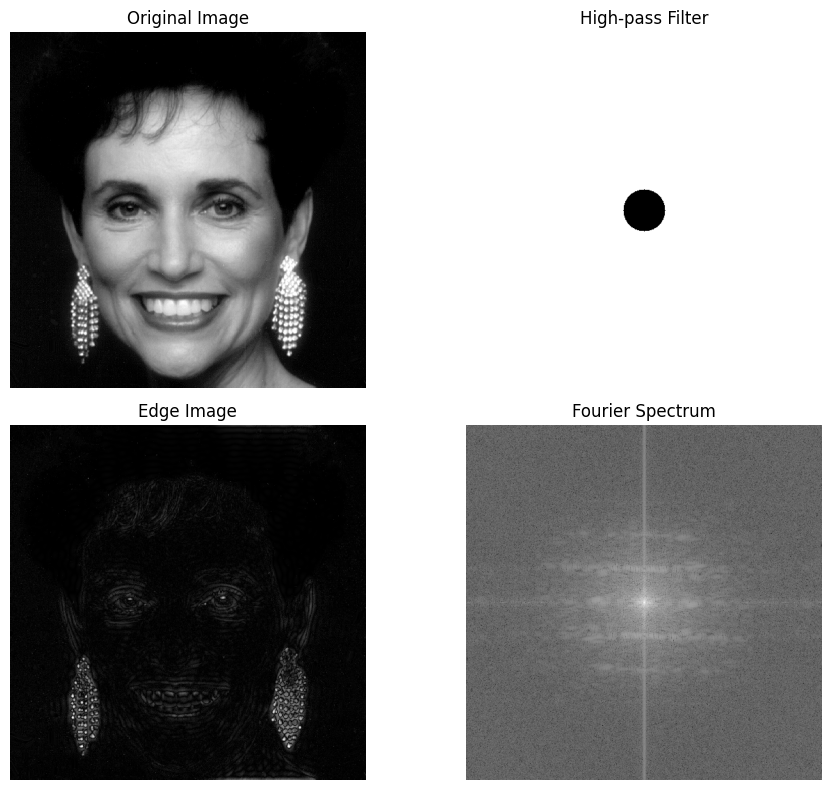

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Đọc ảnh
img_path = r"Fig0427(a)(woman).tif"

img = Image.open(img_path).convert("L")
img = np.array(img)

M, N = img.shape

# 2. Fourier Transform
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

# 3. Tạo High-pass Filter
# H_HP(u,v) = 1 - H_LP(u,v)
# dùng Ideal Low-pass
D0 = 30

u = np.arange(M)
v = np.arange(N)

U, V = np.meshgrid(u, v, indexing='ij')

center_u = M // 2
center_v = N // 2

D = np.sqrt((U-center_u)**2 + (V-center_v)**2)

H_LP = (D <= D0).astype(int)
H_HP = 1 - H_LP

# 4. Áp dụng bộ lọc
# G(u,v) = H_HP(u,v) * F(u,v)
G = H_HP * F_shift

# 5. Fourier ngược
# g(x,y) = F^-1{G(u,v)}
G_ishift = np.fft.ifftshift(G)
img_edge = np.fft.ifft2(G_ishift)
img_edge = np.abs(img_edge)

# 6. Hiển thị kết quả
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.title("Original Image")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("High-pass Filter")
plt.imshow(H_HP, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Edge Image")
plt.imshow(img_edge, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Fourier Spectrum")
plt.imshow(np.log(1 + np.abs(F_shift)), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### **Tách biên bằng bộ lọc thông cao:**

- Bộ lọc thông cao được xây dựng từ bộ lọc thông thấp:

$$
H_{HP}(u,v) = 1 - H_{LP}(u,v)
$$

- Sau khi áp dụng bộ lọc trong miền tần số:

$$
G(u,v) = H_{HP}(u,v)\,F(u,v)
$$

ta thực hiện biến đổi Fourier ngược để thu được ảnh trong miền không gian:

$$
g(x,y) = \mathcal{F}^{-1}\{G(u,v)\}
$$

- Do các cạnh của ảnh tương ứng với các *hành phần tần số cao, bộ lọc thông cao sẽ giữ lại các thành phần này và loại bỏ các tần số thấp.

- Kết quả thu được là ảnh biên, trong đó các cạnh và chi tiết của đối tượng được làm nổi bật.